# CitizenSense ? Final Project Notebook

**AIRI Team | PITB AI Internship | Task 4**

This notebook documents the CitizenSense NLP project using its existing dataset, trained machine-learning models, and saved evaluation outputs.

### Objectives
- Load and inspect the civic feedback dataset.
- Review the existing train, validation, and test splits.
- Evaluate the saved category, sentiment, and priority classifiers.
- Display classification reports and confusion matrices.
- Review transformer evaluation and error-analysis results.

**Important:** This notebook evaluates existing models. It does not retrain or overwrite them.


## 1. Import Libraries and Set Project Paths

In [4]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from IPython.display import display

ROOT = Path.cwd()

if not (ROOT / "data" / "labels.csv").exists():
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "labels.csv"
MODEL_DIR = ROOT / "models"
OUTPUT_DIR = ROOT / "outputs"

print("Project directory:", ROOT)
print("Dataset exists:", DATA_PATH.exists())
print("Models directory exists:", MODEL_DIR.exists())
print("Outputs directory exists:", OUTPUT_DIR.exists())

Project directory: d:\citizensense_nlp_task4
Dataset exists: True
Models directory exists: True
Outputs directory exists: True


## 2. Load and Inspect Dataset

In [5]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\\nColumns:")
print(df.columns.tolist())

print("\\nFirst five records:")
display(df.head())

print("\\nMissing values:")
display(df.isnull().sum())

print("\\nCategory distribution:")
display(df["category"].value_counts())

print("\\nSentiment distribution:")
display(df["sentiment"].value_counts())

print("\\nPriority distribution:")
display(df["priority"].value_counts())

Dataset shape: (500, 8)
\nColumns:
['sample_id', 'text', 'category', 'sentiment', 'priority', 'source_type', 'manual_reviewed', 'split']
\nFirst five records:


,sample_id,text,category,sentiment,priority,source_type,manual_reviewed,split
0,CS-0354,I would like to report lack of educational res...,Education,Positive,Medium,Synthetic,True,train
1,CS-0459,I would like to report lack of information abo...,General,Positive,High,Synthetic,False,test
2,CS-0160,I would like to report irregular water supply....,Water Supply,Positive,Medium,Synthetic,False,test
3,CS-0095,I would like to report frequent power outages....,Electricity,Neutral,Low,Synthetic,True,train
4,CS-0002,I would like to report potholes on the main ro...,Roads / Infrastructure,Positive,Low,Synthetic,False,test


\nMissing values:


sample_id          0
text               0
category           0
sentiment          0
priority           0
source_type        0
manual_reviewed    0
split              0
dtype: int64

\nCategory distribution:


category
Water Supply              63
Electricity               63
Roads / Infrastructure    63
Sanitation                63
Education                 62
General                   62
Health                    62
Traffic                   62
Name: count, dtype: int64

\nSentiment distribution:


sentiment
Neutral     181
Positive    169
Negative    150
Name: count, dtype: int64

\nPriority distribution:


priority
Low       176
High      174
Medium    150
Name: count, dtype: int64

## 3. Dataset Split Verification

The intended split is 70% training, 15% validation, and 15% testing.

The following cell verifies the saved split rather than creating a new one.

In [6]:
split_counts = df["split"].value_counts()
display(split_counts)

split_summary = pd.DataFrame({
    "Samples": split_counts,
    "Percentage": (split_counts / len(df) * 100).round(2)
})
display(split_summary)

assert set(df["split"].unique()).issubset(
    {"train", "validation", "test"}
), "Unexpected split name found."

print("Total samples:", len(df))

split
train         350
test           75
validation     75
Name: count, dtype: int64

,Samples,Percentage
split,,
train,350,70.0
test,75,15.0
validation,75,15.0


Total samples: 500


## 4. Load Existing Trained Models

The saved Logistic Regression classifiers and TF-IDF vectorizers are loaded from the project's `models` directory. No training or model modification is performed.

In [7]:
baseline_model = joblib.load(MODEL_DIR / "baseline_model.pkl")
tfidf_vectorizer = joblib.load(MODEL_DIR / "tfidf_vectorizer.pkl")

sentiment_model = joblib.load(MODEL_DIR / "sentiment_model.pkl")
priority_model = joblib.load(MODEL_DIR / "priority_model.pkl")
attribute_vectorizer = joblib.load(MODEL_DIR / "attribute_vectorizer.pkl")

print("Category model:", type(baseline_model).__name__)
print("Category classes:", baseline_model.classes_)

print("\\nSentiment model:", type(sentiment_model).__name__)
print("Sentiment classes:", sentiment_model.classes_)

print("\\nPriority model:", type(priority_model).__name__)
print("Priority classes:", priority_model.classes_)

Category model: LogisticRegression
Category classes: ['Education' 'Electricity' 'General' 'Health' 'Roads / Infrastructure'
 'Sanitation' 'Traffic' 'Water Supply']
\nSentiment model: LogisticRegression
Sentiment classes: ['Negative' 'Neutral' 'Positive']
\nPriority model: LogisticRegression
Priority classes: ['High' 'Low' 'Medium']


## 5. Prepare Test Data

Only records assigned to the existing test split are used for evaluation. The models are evaluated against their corresponding actual labels.

In [8]:
test_df = df[df["split"] == "test"].copy()

X_category = tfidf_vectorizer.transform(test_df["text"].fillna(""))
X_attributes = attribute_vectorizer.transform(test_df["text"].fillna(""))

y_category = test_df["category"]
y_sentiment = test_df["sentiment"]
y_priority = test_df["priority"]

print("Test samples:", len(test_df))
print("Category feature shape:", X_category.shape)
print("Attribute feature shape:", X_attributes.shape)

Test samples: 75
Category feature shape: (75, 687)
Attribute feature shape: (75, 687)


## 6. Evaluate Category Classification

Category Accuracy: 0.9867
\nCategory Classification Report:
                        precision    recall  f1-score   support

             Education       1.00      1.00      1.00         9
           Electricity       0.90      1.00      0.95         9
               General       1.00      1.00      1.00         9
                Health       1.00      1.00      1.00        10
Roads / Infrastructure       1.00      1.00      1.00        10
            Sanitation       1.00      1.00      1.00        10
               Traffic       1.00      1.00      1.00         9
          Water Supply       1.00      0.89      0.94         9

              accuracy                           0.99        75
             macro avg       0.99      0.99      0.99        75
          weighted avg       0.99      0.99      0.99        75



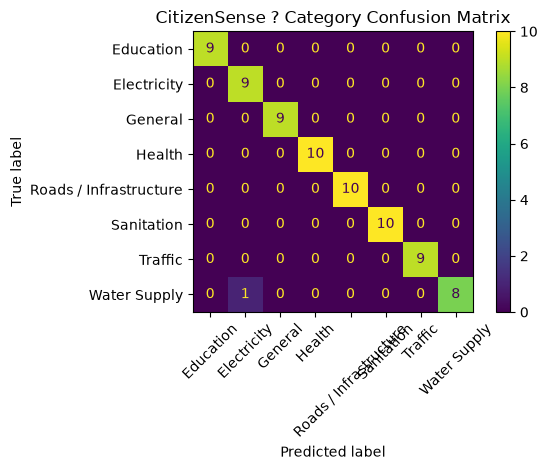

In [9]:
category_predictions = baseline_model.predict(X_category)

print("Category Accuracy:", round(
    accuracy_score(y_category, category_predictions), 4
))
print("\\nCategory Classification Report:")
print(classification_report(
    y_category,
    category_predictions,
    zero_division=0
))

category_cm = confusion_matrix(
    y_category,
    category_predictions,
    labels=baseline_model.classes_
)

display = ConfusionMatrixDisplay(
    confusion_matrix=category_cm,
    display_labels=baseline_model.classes_
)
display.plot(xticks_rotation=45)
plt.title("CitizenSense ? Category Confusion Matrix")
plt.tight_layout()
plt.show()

## 7. Evaluate Sentiment Classification

Sentiment Accuracy: 1.0
\nSentiment Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        23
     Neutral       1.00      1.00      1.00        31
    Positive       1.00      1.00      1.00        21

    accuracy                           1.00        75
   macro avg       1.00      1.00      1.00        75
weighted avg       1.00      1.00      1.00        75



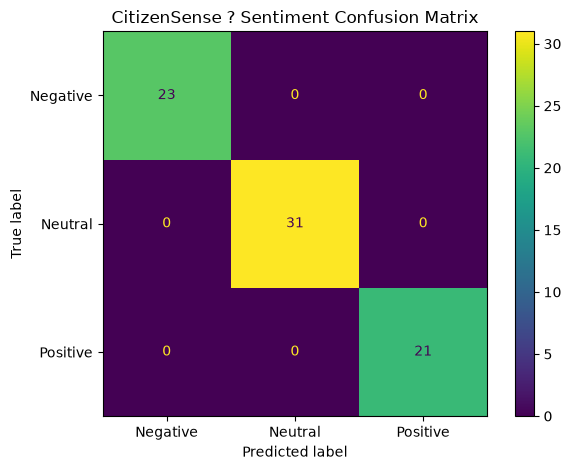

In [10]:
sentiment_predictions = sentiment_model.predict(X_attributes)

print("Sentiment Accuracy:", round(
    accuracy_score(y_sentiment, sentiment_predictions), 4
))
print("\\nSentiment Classification Report:")
print(classification_report(
    y_sentiment,
    sentiment_predictions,
    zero_division=0
))

sentiment_cm = confusion_matrix(
    y_sentiment,
    sentiment_predictions,
    labels=sentiment_model.classes_
)

display = ConfusionMatrixDisplay(
    confusion_matrix=sentiment_cm,
    display_labels=sentiment_model.classes_
)
display.plot()
plt.title("CitizenSense ? Sentiment Confusion Matrix")
plt.tight_layout()
plt.show()

## 8. Evaluate Priority Classification

Priority Accuracy: 1.0
\nPriority Classification Report:
              precision    recall  f1-score   support

        High       1.00      1.00      1.00        29
         Low       1.00      1.00      1.00        19
      Medium       1.00      1.00      1.00        27

    accuracy                           1.00        75
   macro avg       1.00      1.00      1.00        75
weighted avg       1.00      1.00      1.00        75



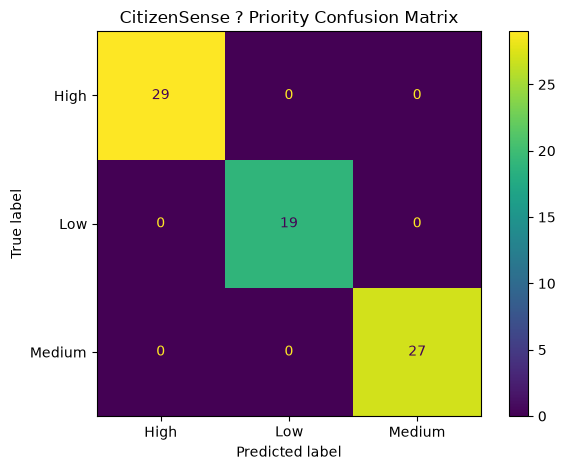

In [11]:
priority_predictions = priority_model.predict(X_attributes)

print("Priority Accuracy:", round(
    accuracy_score(y_priority, priority_predictions), 4
))
print("\\nPriority Classification Report:")
print(classification_report(
    y_priority,
    priority_predictions,
    zero_division=0
))

priority_cm = confusion_matrix(
    y_priority,
    priority_predictions,
    labels=priority_model.classes_
)

display = ConfusionMatrixDisplay(
    confusion_matrix=priority_cm,
    display_labels=priority_model.classes_
)
display.plot()
plt.title("CitizenSense ? Priority Confusion Matrix")
plt.tight_layout()
plt.show()

## 9. Review Saved Transformer Evaluation

The project also contains a saved evaluation report for the Hugging Face transformer sentiment pipeline. This cell displays the existing report; it does not rerun the transformer.

In [12]:
transformer_report_path = OUTPUT_DIR / "transformer_classification_report.txt"

if transformer_report_path.exists():
    print(transformer_report_path.read_text(encoding="utf-8"))
else:
    print("Transformer classification report was not found.")

              precision    recall  f1-score   support

    negative       0.48      1.00      0.65        23
     neutral       0.48      0.32      0.38        31
    positive       1.00      0.29      0.44        21

    accuracy                           0.52        75
   macro avg       0.65      0.54      0.49        75
weighted avg       0.62      0.52      0.48        75



## 10. Review Error Analysis

In [14]:
error_path = OUTPUT_DIR / "error_analysis.csv"

if error_path.exists():
    errors = pd.read_csv(error_path)

    print("Records selected for review:", len(errors))

    from IPython.display import display as show_table
    show_table(errors.head(15))

    if "correct_prediction" in errors.columns:
        print("\nPrediction status:")
        show_table(
            errors["correct_prediction"].value_counts(dropna=False)
        )

else:
    print("Error analysis file was not found.")

Records selected for review: 15


,sample_id,text,category,predicted_category,confidence,correct_prediction,analysis_type
0,CS-0131,I would like to report irregular water supply....,Water Supply,Electricity,0.2380,False,Misclassified
1,CS-0026,I would like to report broken streetlights. Pl...,Roads / Infrastructure,Roads / Infrastructure,0.2312,True,Low-confidence review
2,CS-0005,I would like to report damaged road surfaces. ...,Roads / Infrastructure,Roads / Infrastructure,0.2388,True,Low-confidence review
3,CS-0160,I would like to report irregular water supply....,Water Supply,Water Supply,0.2678,True,Low-confidence review
4,CS-0010,I would like to report poor road maintenance. ...,Roads / Infrastructure,Roads / Infrastructure,0.2783,True,Low-confidence review
5,CS-0123,I would like to report low voltage in resident...,Electricity,Electricity,0.2878,True,Low-confidence review
6,CS-0069,I would like to report damaged public power in...,Electricity,Electricity,0.2984,True,Low-confidence review
7,CS-0247,I would like to report uncollected garbage. Th...,Sanitation,Sanitation,0.3073,True,Low-confidence review
8,CS-0128,I would like to report shortage of clean drink...,Water Supply,Water Supply,0.3096,True,Low-confidence review
9,CS-0413,I would like to report poor public transport c...,Traffic,Traffic,0.3167,True,Low-confidence review



Prediction status:


correct_prediction
True     14
False     1
Name: count, dtype: int64

## 11. Evaluation Summary

The previously generated project reports recorded these test results:

| Model | Recorded Accuracy |
|---|---:|
| TF-IDF + Logistic Regression (Category) | 98.67% |
| Sentiment Classifier | 100% |
| Priority Classifier | 100% |
| Hugging Face RoBERTa Sentiment Pipeline | 52% |

The evaluation cells above calculate metrics again from the saved models and test split. Their outputs should be used to verify these recorded figures.

## 12. Limitations and Responsible Use

- The dataset contains 500 synthetic civic feedback samples.
- The 200 records marked as reviewed do not currently have established independent human-annotation evidence.
- High scores on synthetic data do not guarantee similar performance on real complaints.
- The transformer pipeline has lower recorded accuracy on this test set.
- Model confidence is an estimate, not certainty.
- Suggested departments are informational and require human review.

## 13. Conclusion

CitizenSense demonstrates a practical NLP workflow combining text preprocessing, TF-IDF, machine-learning classification, transformer-based sentiment analysis, model evaluation, error analysis, and an interactive Streamlit dashboard.

Further validation using independently annotated real-world feedback is needed before real-world deployment.

**Project:** CitizenSense  AIRI Team PITB Internship Task 4
